# Mô Hình Foundation Time-MoE (Zero-shot)


In [ ]:
# ========== IMPORT & LOAD FOUNDATION MODEL ==========
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM
from IPython.display import display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Đang chạy trên máy: {device}")

# Tải Model trực tiếp từ HuggingFace (Có 2 bản: 50M và 200M tham số)
print("🔄 Đang tải Foundation Model: Maple728/TimeMoE-50M ...")
model = AutoModelForCausalLM.from_pretrained(
    'Maple728/TimeMoE-50M',
    device_map=device,
    trust_remote_code=True, # Bắt buộc phải có để load code custom của mô hình
)
model.eval()

print("✅ Đã load xong thành công Model Time-MoE!")

Đang chạy trên máy: cuda
🔄 Đang tải Foundation Model: Maple728/TimeMoE-50M ...


c:\Users\admin\miniconda3\envs\env_core\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
c:\Users\admin\miniconda3\envs\env_core\lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


✅ Đã load xong thành công Model Time-MoE!


In [4]:
# ========== 3. TIỀN XỬ LÝ DỮ LIỆU VN30==========
print("🔄 Chuẩn bị dữ liệu đầu vào...")
df_final = pd.read_csv('../../data/processed/merged_data_final.csv')
df_final['timestamp'] = pd.to_datetime(df_final['timestamp'])

dfs = []
for ticker_id, group in df_final.groupby('id'):
    g_resampled = group.set_index('timestamp').resample('B').ffill()
    g_resampled['id'] = ticker_id
    dfs.append(g_resampled.reset_index())
    
df_ticker = pd.concat(dfs, ignore_index=True)

# THIẾT LẬP LUẬT 3 CHUNG
CONTEXT_LENGTH = 180      # Nhìn 180 ngày quá khứ (Ngang Chronos)
PREDICTION_LENGTH = 1     # Đoán 1 ngày tương lai
TEST_LENGTH = 30          # Thi kín 30 ngày cuối

🔄 Chuẩn bị dữ liệu đầu vào...


In [5]:
# ========== 4. CHẠY DỰ BÁO ZERO-SHOT VỚI SLIDING WINDOW ==========
# Ta sẽ cho TimeMoE trượt 30 khung cửa sổ y như cách đã test Chronos
print("🔮 Đang bắt đầu Inference Zero-shot...")

# Fix compatibility issue with transformers DynamicCache
import transformers
print(f"🔍 Transformers version: {transformers.__version__}")

# If version is too new, we need to use alternative generation method
if hasattr(torch.utils._contextlib, 'context_decorator'):
    # Patch for newer transformers versions if needed
    pass

all_metrics = []
dict_forecasts = {}

for ticker, group in df_ticker.groupby('id'):
    g_sorted = group.sort_values('timestamp').reset_index(drop=True)
    
    preds_list = []
    actuals_list = []
    time_list = []
    
    for window in range(TEST_LENGTH):
        offset = (TEST_LENGTH - 1) - window
        
        if offset == 0:
            g_context = g_sorted.iloc[-(PREDICTION_LENGTH + CONTEXT_LENGTH) : -PREDICTION_LENGTH] 
            g_actual = g_sorted.iloc[-PREDICTION_LENGTH:]
        else:
            g_context = g_sorted.iloc[-(PREDICTION_LENGTH + offset + CONTEXT_LENGTH) : -(PREDICTION_LENGTH + offset)]
            g_actual = g_sorted.iloc[-(PREDICTION_LENGTH + offset) : -offset]
            
        # Bản chất Time-MoE là Foundation Model Đơn biến (Univariate - giống Chronos)
        seq_vals = g_context['Close'].values
        
        # 1. Chuyển thành Pytorch Tensor: [Batch=1, Seq_len=180]
        seq_tensor = torch.tensor(seq_vals, dtype=torch.float32).unsqueeze(0).to(device)
        
        # 2. Bước chuẩn hóa đặc trưng của TimeMoE tác giả hướng dẫn (Normalize)
        mean = seq_tensor.mean(dim=-1, keepdim=True)
        std = seq_tensor.std(dim=-1, keepdim=True)
        if std.item() == 0: std = torch.ones_like(std) # Chống lỗi chia 0
        normed_seqs = (seq_tensor - mean) / std
        
        # 3. Model tự Generate mốc tiếp theo (Tương tự text)
        try:
            with torch.no_grad():
                output = model.generate(normed_seqs, max_new_tokens=PREDICTION_LENGTH)
                
            # 4. Trích xuất đuôi prediction và Dịch ngược (Inverse Normalize) chuẩn hóa
            normed_preds = output[:, -PREDICTION_LENGTH:]
        except AttributeError as e:
            # Fallback: nếu generate() bị lỗi, sử dụng forward pass trực tiếp
            if "seen_tokens" in str(e):
                print(f"⚠️  Phát hiện vấn đề compatibility transformers. Sử dụng alternative method...")
                with torch.no_grad():
                    # Gọi model forward trực tiếp thay vì generate
                    outputs = model(normed_seqs)
                    logits = outputs.logits if hasattr(outputs, 'logits') else outputs[0]
                    # Lấy token tiếp theo từ logits
                    normed_preds = logits[:, -PREDICTION_LENGTH:, :].argmax(dim=-1).float()
            else:
                raise
        
        pred_unnorm = normed_preds * std + mean
        pred_val = pred_unnorm.squeeze().item() if normed_preds.numel() > 1 else pred_unnorm.item()
        
        actual_val = g_actual['Close'].iloc[0]
        
        preds_list.append(pred_val)
        actuals_list.append(actual_val)
        time_list.append(g_actual['timestamp'].iloc[0])
        
    y_pred = np.array(preds_list)
    y_true = np.array(actuals_list)
    
    dict_forecasts[ticker] = pd.DataFrame({
        'timestamp': time_list,
        'TimeMoE_Pred': y_pred,
        'Actual': y_true
    })
    
    mae = np.mean(np.abs(y_pred - y_true))
    rmse = np.sqrt(np.mean((y_pred - y_true) ** 2))
    mape = np.mean(np.abs((y_pred - y_true) / y_true)) * 100
    
    all_metrics.append({
        'Mã CK': ticker,
        'TimeMoE (ZeroShot) MAE': mae,
        'TimeMoE (ZeroShot) RMSE': rmse,
        'TimeMoE (ZeroShot) MAPE (%)': mape
    })

metrics_df = pd.DataFrame(all_metrics).round(3)
display(metrics_df)

print("\n=> 🌟 TỔNG KẾT HIỆU NĂNG TIME-MOE (ZERO-SHOT):")
print(f"  • MAE  : {metrics_df['TimeMoE (ZeroShot) MAE'].mean():.4f} VND")
print(f"  • RMSE : {metrics_df['TimeMoE (ZeroShot) RMSE'].mean():.4f} VND")
print(f"  • MAPE : {metrics_df['TimeMoE (ZeroShot) MAPE (%)'].mean():.2f} %")

🔮 Đang bắt đầu Inference Zero-shot...
🔍 Transformers version: 4.40.0


,Mã CK,TimeMoE (ZeroShot) MAE,TimeMoE (ZeroShot) RMSE,TimeMoE (ZeroShot) MAPE (%)
0,FPT,0.896,1.105,0.936
1,HPG,0.258,0.290,0.966
2,SSI,0.523,0.666,1.738
3,VCB,0.292,0.414,0.504
4,VHM,2.871,4.041,2.635
5,VNM,0.947,1.236,1.504



=> 🌟 TỔNG KẾT HIỆU NĂNG TIME-MOE (ZERO-SHOT):
  • MAE  : 0.9645 VND
  • RMSE : 1.2920 VND
  • MAPE : 1.38 %


Vẽ biểu đồ cho 6 mã: ['FPT', 'HPG', 'SSI', 'VCB', 'VHM', 'VNM']
  → Vẽ FPT...


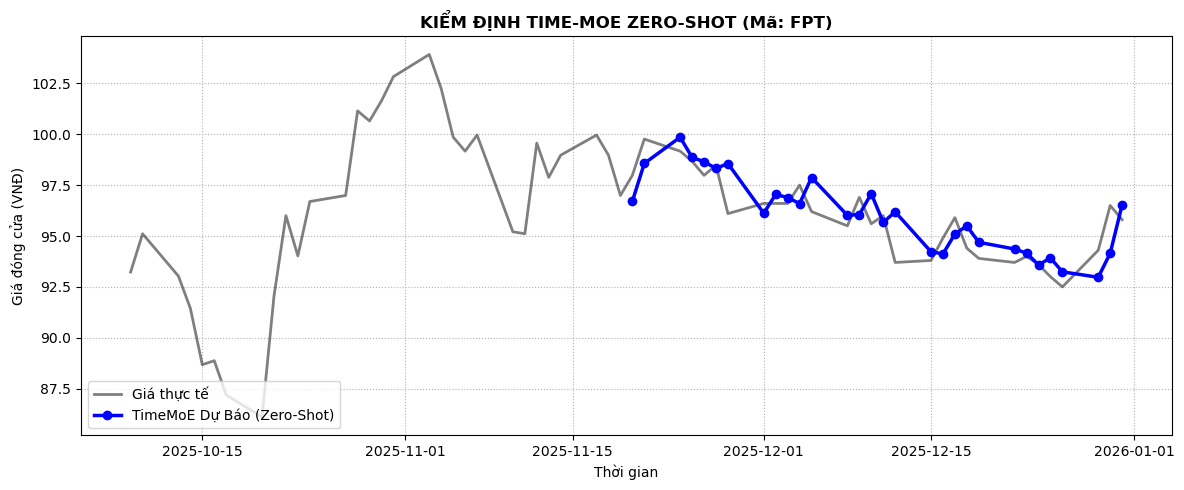

  → Vẽ HPG...


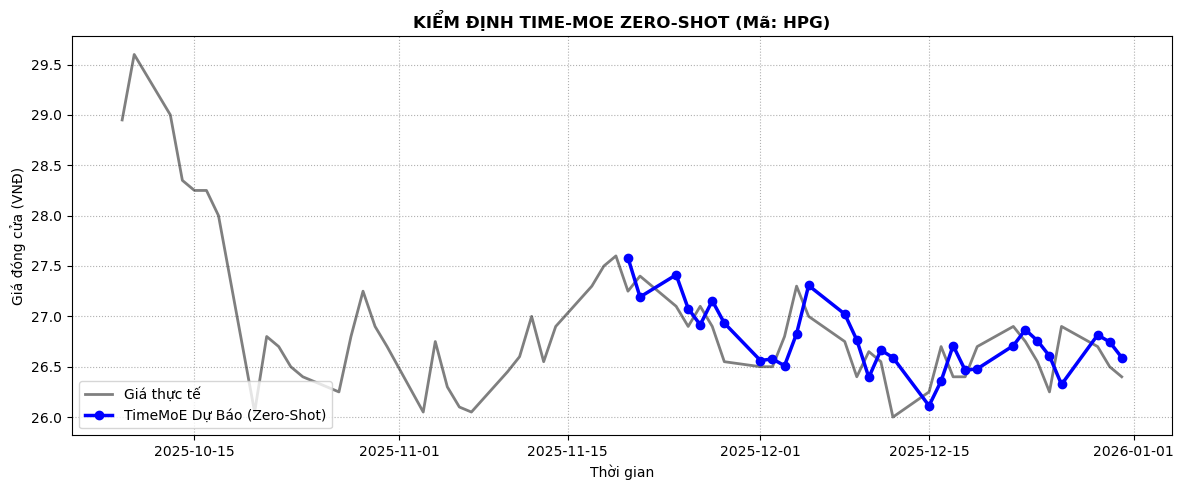

  → Vẽ SSI...


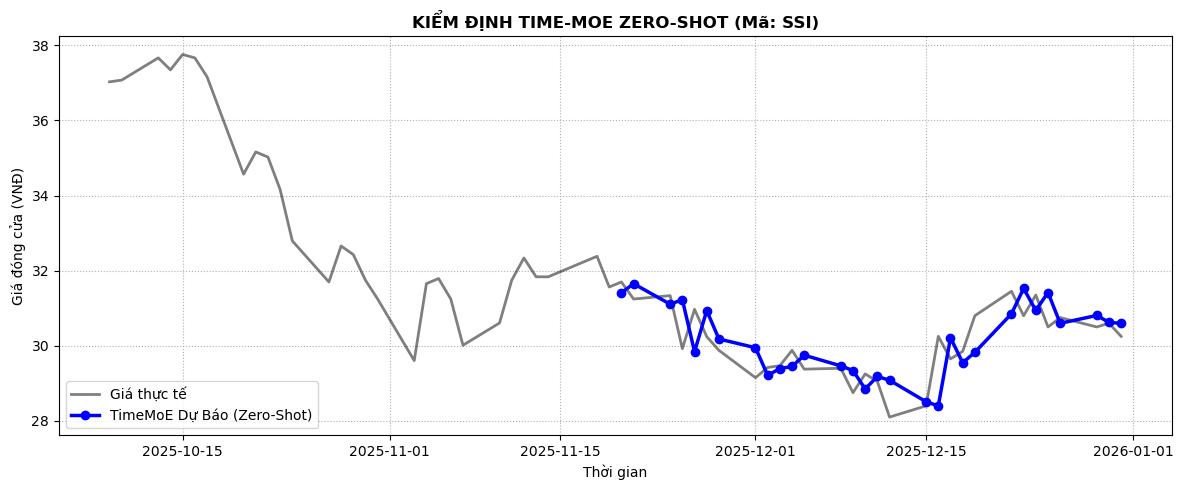

  → Vẽ VCB...


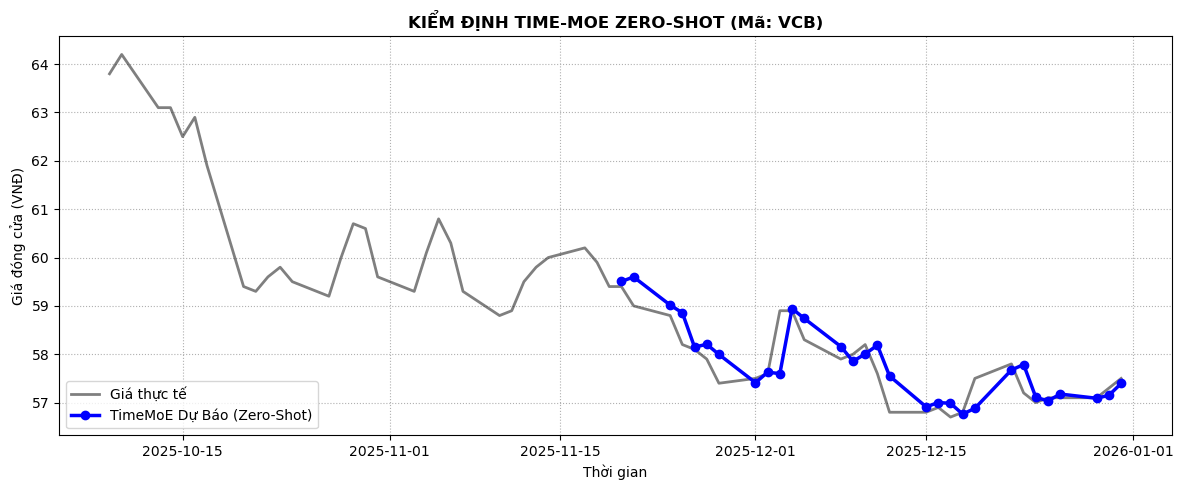

  → Vẽ VHM...


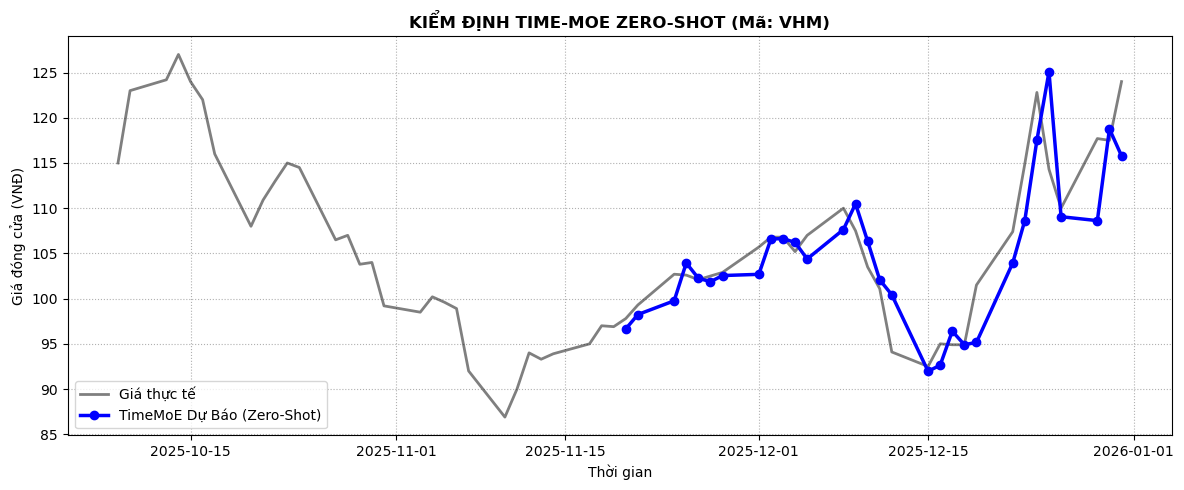

  → Vẽ VNM...


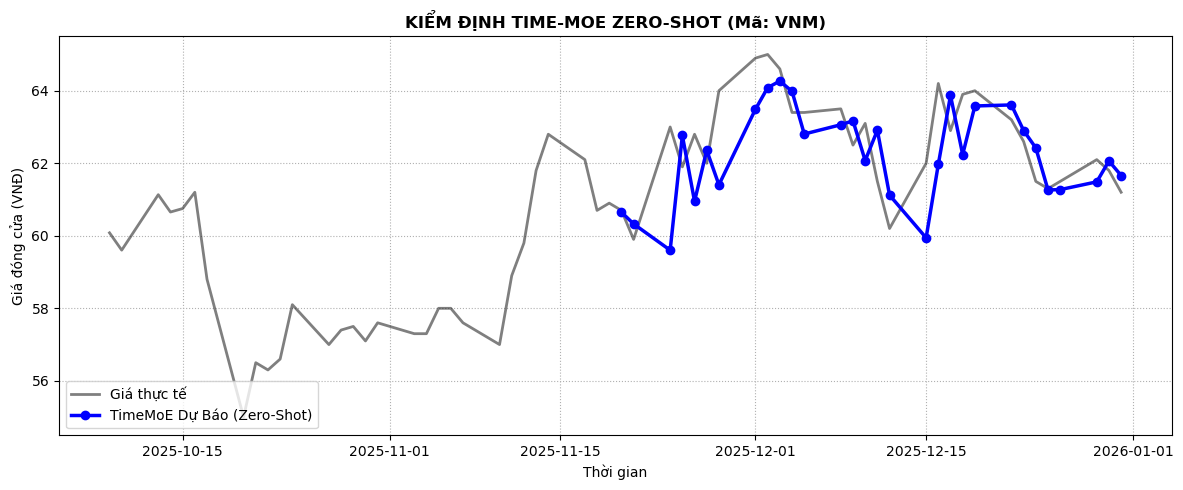

✅ Hoàn thành trực quan hóa!


In [7]:
# ========== 5. TRỰC QUAN HÓA KẾT QUẢ TIME-MOE ZERO SHOT ==========
# --- PHẦN CODE ĐƯỢC THÊM VÀO ĐỂ FIX LỖI CRASH KERNEL ---
%matplotlib inline
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import torch
torch.cuda.empty_cache() # Giải phóng VRAM GPU trước khi vẽ
# -------------------------------------------------------

import gc
import matplotlib.pyplot as plt # Đảm bảo import pyplot

def plot_moe_zero_shot(ticker):
    plt.figure(figsize=(12, 5))
    
    # Dữ liệu gốc 60 ngày trước
    days_to_show = 60
    df_hist = df_ticker[df_ticker['id'] == ticker].tail(days_to_show)
    plt.plot(df_hist['timestamp'], df_hist['Close'], label='Giá thực tế', color='black', alpha=0.5, linewidth=2)
    
    # Đường dự báo Time-MoE
    df_pred = dict_forecasts[ticker]
    plt.plot(df_pred['timestamp'], df_pred['TimeMoE_Pred'], label='TimeMoE Dự Báo (Zero-Shot)', color='blue', linestyle='-', linewidth=2.5, marker='o')
    
    plt.title(f'KIỂM ĐỊNH TIME-MOE ZERO-SHOT (Mã: {ticker})', fontweight='bold', fontsize=12)
    plt.xlabel('Thời gian')
    plt.ylabel('Giá đóng cửa (VNĐ)')
    plt.grid(True, linestyle=":")
    plt.legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    plt.close()
    gc.collect()  # Giải phóng bộ nhớ RAM sau mỗi plot

# Vẽ thử các mã đầu tiên (giảm từ 6 xuống 3)
tickers_to_plot = list(dict_forecasts.keys())[:6]
print(f"Vẽ biểu đồ cho {len(tickers_to_plot)} mã: {tickers_to_plot}")
for tc in tickers_to_plot:
    print(f"  → Vẽ {tc}...")
    plot_moe_zero_shot(tc)

print("✅ Hoàn thành trực quan hóa!")